# 02 · Pulizia dei dati e registro delle esclusioni

**Obiettivo.** Trasformare i dati grezzi integrati (passo 01-02) in due insiemi pronti per l'analisi:

1. **Misure di attività su PDE4** → `activities_clean` (una riga per misura, con pIC50/pKi) e `activity_potency` (mediana per molecola e bersaglio).
2. **Farmaci inalatori vs orali** → `inhalation_dataset` (una riga per molecola, gruppi esclusivi).

**Regole del gioco.**
- Le tabelle grezze non vengono modificate: tutto ciò che è pulito finisce in tabelle nuove.
- Le regole si applicano in ordine; ogni regola vede solo le righe sopravvissute alle precedenti, quindi **ogni riga esclusa ha un solo motivo**.
- Il **registro delle esclusioni** (`cleaning_log` + `cleaning_exclusions`) dice quante righe toglie ogni regola, perché, e quali sono.

La logica sta in `src/cleaning.py` (riusabile e testabile); questo notebook la esegue passo per passo e mostra le prove.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import cleaning

con = sqlite3.connect(ROOT / "data" / "processed" / "pharma_inhalation.sqlite")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True})
COLORS = {"inhaled": "#2a78d6", "oral": "#eb6834"}
LOG_COLUMNS = ["rule_id", "kind", "rule", "rows_before", "rows_removed", "rows_after", "rows_flagged"]

pd.read_sql_query("SELECT key, value FROM dataset_info WHERE key NOT LIKE 'sha256:%' AND key NOT LIKE 'retrieved_at:%'", con)

,key,value
0,chembl_release,ChEMBL_37
1,chembl_release_date,2026-05-01
2,openfda_last_updated,2026-10-20
3,built_at,2026-10-21T12:01:43+00:00


## Parte A · Misure di attività su PDE4

### A.1 Prima di pulire: quali problemi ci sono?
Una misura di potenza è affidabile solo se è un valore puntuale (`=`), in un'unità di concentrazione, senza segnalazioni dei curatori. Contiamo i casi con SQL direttamente sulle tabelle grezze.

In [2]:
pd.read_sql_query("""
    SELECT COALESCE(standard_relation, '(vuota)') AS relazione, COUNT(*) AS misure
    FROM activities
    GROUP BY 1
    ORDER BY misure DESC
""", con)

,relazione,misure
0,=,8979
1,<,1442
2,>,1213
3,(vuota),314
4,>=,5
5,<=,1


Le unità pubblicate negli articoli sono eterogenee (nM, µM, mM, perfino `10'3nM`). ChEMBL le converte in nM nella colonna `standard_units`: per questo il programma usa i valori standardizzati e non quelli pubblicati.

In [3]:
pd.read_sql_query("""
    SELECT COALESCE(published_units, '(vuota)') AS unita_pubblicate,
           COALESCE(standard_units, '(vuota)')  AS unita_standard,
           COUNT(*) AS misure
    FROM activities
    GROUP BY 1, 2
    ORDER BY misure DESC
""", con)

,unita_pubblicate,unita_standard,misure
0,nM,nM,7551
1,uM,nM,3304
2,(vuota),nM,677
3,(vuota),(vuota),292
4,mM,nM,86
5,10'3nM,nM,12
6,%,%,10
7,pM,nM,10
8,M,nM,7
9,10'-3microM,nM,2


### A.2 Applicazione delle regole
Per ogni misura pulita la potenza diventa un logaritmo: **pX = 9 − log10(valore in nM)**. Un IC50 di 10 nM corrisponde a pIC50 = 8; ogni unità in più significa 10 volte più potente. La scala logaritmica rende confrontabili valori che vanno da picomolare a millimolare e permette di usare la mediana.

In [4]:
raw_activities = cleaning.load_activities(con)
activities, potency, ledger_a = cleaning.clean_activities(raw_activities)
log_a = ledger_a.log_frame()
log_a[LOG_COLUMNS]

,rule_id,kind,rule,rows_before,rows_removed,rows_after,rows_flagged
0,A0,input,Misure IC50 e Ki sulle PDE4 umane scaricate da ChEMBL,11954,0,11954,0
1,A1,exclude,Misure segnalate dai curatori ChEMBL,11954,259,11695,0
2,A2,exclude,Relazione diversa da '=',11695,2892,8803,0
3,A3,exclude,Unità standard diversa da nM,8803,10,8793,0
4,A4,exclude,Valore mancante o non positivo,8793,0,8793,0
5,A5,exclude,pIC50/pKi fuori da 3-12,8793,0,8793,0
6,A6,check,Confronto con il pChEMBL calcolato da ChEMBL,8793,0,8793,0
7,A7,aggregate,Mediana delle misure ripetute,8793,0,6887,0
8,A8,check,Repliche distanti più di 1 unità log,6887,0,6887,208


In [5]:
log_a.loc[log_a["kind"] != "input", ["rule_id", "rule", "reason"]]

,rule_id,rule,reason
1,A1,Misure segnalate dai curatori ChEMBL,"Il campo data_validity_comment indica un valore sospetto (unità, trascrizione, fuori scala)."
2,A2,Relazione diversa da '=',"I valori censurati (<, >) dicono solo che la potenza è sopra o sotto una soglia: non sono una stima puntuale."
3,A3,Unità standard diversa da nM,Percentuali o unità mancanti non si convertono in una concentrazione.
4,A4,Valore mancante o non positivo,Il logaritmo richiede un valore numerico maggiore di zero.
5,A5,pIC50/pKi fuori da 3-12,Una potenza sotto 1 mM o sopra 1 pM è quasi sempre un errore di unità.
6,A6,Confronto con il pChEMBL calcolato da ChEMBL,Segnala le misure in cui il pX calcolato differisce più di 0.05 da pChEMBL.
7,A7,Mediana delle misure ripetute,Una riga per molecola × bersaglio × tipo di misura; la mediana resiste ai valori anomali.
8,A8,Repliche distanti più di 1 unità log,Coppie con misure che differiscono più di 10 volte: tenute ma segnalate.


Il controllo **A6** confronta il pX calcolato qui con il `pchembl_value` che ChEMBL calcola per conto suo: se le due strade danno lo stesso numero, la conversione è corretta. Il controllo **A8** segnala le coppie molecola-bersaglio le cui misure differiscono più di 10 volte: restano nei dati, ma vanno guardate prima di trarre conclusioni su quella molecola.

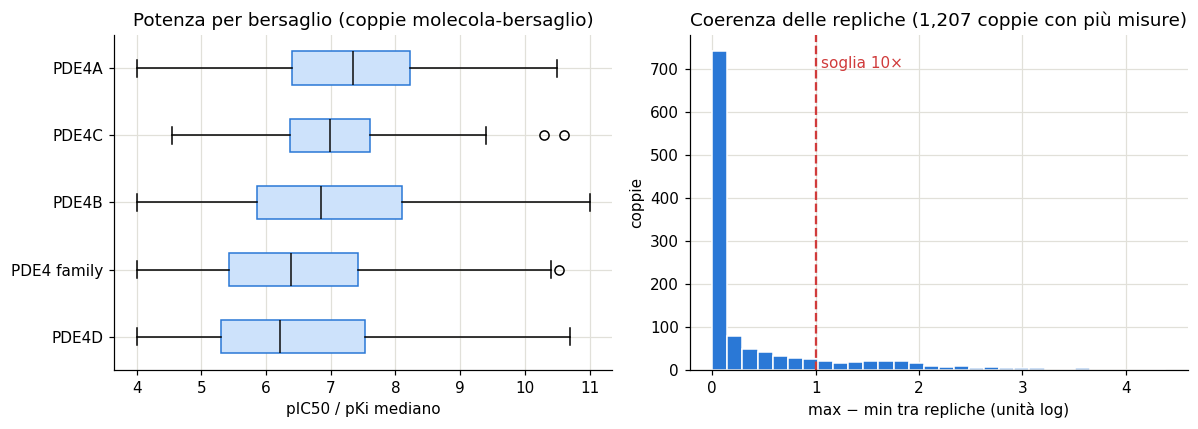

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = potency.groupby("target_name")["p_median"].median().sort_values().index
axes[0].boxplot([potency.loc[potency.target_name == t, "p_median"] for t in order],
                tick_labels=order, vert=False, patch_artist=True,
                boxprops={"facecolor": "#cde2fb", "color": "#2a78d6"}, medianprops={"color": "#0b0b0b"})
axes[0].set_xlabel("pIC50 / pKi mediano")
axes[0].set_title("Potenza per bersaglio (coppie molecola-bersaglio)")

replicated = potency[potency.n_measurements > 1]
axes[1].hist(replicated["p_range"], bins=30, color="#2a78d6", edgecolor="white")
axes[1].axvline(cleaning.INCONSISTENT_RANGE, color="#d03b3b", linestyle="--", linewidth=1.5)
axes[1].text(cleaning.INCONSISTENT_RANGE + 0.05, axes[1].get_ylim()[1] * 0.9, "soglia 10×", color="#d03b3b")
axes[1].set_xlabel("max − min tra repliche (unità log)")
axes[1].set_ylabel("coppie")
axes[1].set_title(f"Coerenza delle repliche ({len(replicated):,} coppie con più misure)")
fig.tight_layout()
fig.savefig(FIG / "activities_potency.png", bbox_inches="tight")
plt.show()

## Parte B · Farmaci inalatori vs orali

### B.1 Il campo "via di somministrazione" non è uniforme
Lo stesso concetto è scritto in modi diversi: una sola via, più vie separate da virgola, maiuscole e minuscole. Prima della pulizia solo il testo esatto `INHALATION` veniva riconosciuto.

In [7]:
pd.read_sql_query("""
    SELECT route, COUNT(*) AS prodotti
    FROM fda_products
    WHERE UPPER(route) LIKE '%INHAL%'
    GROUP BY route
    ORDER BY prodotti DESC
""", con)

,route,prodotti
0,INHALATION,609
1,"INHALATION, ORAL",21
2,"Inhalation, Oral",2
3,"INHALATION, INTRAVENOUS",2
4,"INHALATION, INJECTION",1


### B.2 Applicazione delle regole
Tre trasformazioni preparano i dati (M0a-M0c), poi sei regole escludono le molecole che non rispondono alla domanda. La logica delle esclusioni M5 e M6 è simmetrica:
- un inalatorio che agisce sul **sistema nervoso** viene inalato per arrivare nel sangue (anestetici, loxapina, levodopa): non rappresenta un farmaco che deve restare nel polmone;
- un orale che agisce **solo nell'intestino** è progettato per non essere assorbito: non rappresenta un farmaco orale sistemico.

In [8]:
dataset, routes, ledger_m = cleaning.clean_molecules(con)
log_m = ledger_m.log_frame()
log_m[LOG_COLUMNS]

,rule_id,kind,rule,rows_before,rows_removed,rows_after,rows_flagged
0,M0,input,Molecole parent con almeno un prodotto FDA orale o inalatorio,1305,0,1305,0
1,M0a,transform,Vie di somministrazione separate e in maiuscolo,1305,0,1305,0
2,M0b,transform,Codici ATC ereditati dai sali,1305,0,1305,0
3,M0c,transform,Gruppi esclusivi: inalatorio prevale su orale,1305,0,1305,15
4,M1,exclude,Non è una piccola molecola,1305,37,1268,0
5,M2,exclude,Proprietà chimiche principali mancanti,1268,63,1205,0
6,M3,exclude,Gas medicali,1205,10,1195,0
7,M4,exclude,Solo diagnostici,1195,12,1183,0
8,M5,exclude,Inalatori ad azione sistemica sul sistema nervoso,1183,9,1174,0
9,M6,exclude,Orali ad azione locale nell'intestino,1174,20,1154,0


In [9]:
log_m.loc[log_m["kind"].isin(["transform", "exclude"]), ["rule_id", "rule", "reason"]]

,rule_id,rule,reason
1,M0a,Vie di somministrazione separate e in maiuscolo,"""INHALATION, ORAL"" e ""Inhalation, Oral"" contano per entrambe le vie: le molecole inalatorie passano da 65 ..."
2,M0b,Codici ATC ereditati dai sali,Molti codici ATC sono registrati sul sale (es. tiotropio bromuro): vengono attribuiti alla molecola parent.
3,M0c,Gruppi esclusivi: inalatorio prevale su orale,Una molecola con prodotti inalatori va nel gruppo inhaled (also_oral = 1 se esiste anche per bocca); il gr...
4,M1,Non è una piccola molecola,Proteine e miscele non hanno proprietà calcolate confrontabili.
5,M2,Proprietà chimiche principali mancanti,"Servono tutte: mw_freebase, alogp, psa, hbd, hba. Mancano per ioni e gas nobili."
6,M3,Gas medicali,"Peso molecolare sotto 100 Da o ATC V03AN (ossigeno, azoto, protossido...): non sono farmaci progettati."
7,M4,Solo diagnostici,"Tutti i codici ATC sono V04/V08/V09 (test di provocazione, mezzi di contrasto, radiofarmaci)."
8,M5,Inalatori ad azione sistemica sul sistema nervoso,"ATC di primo livello N (anestetici volatili, loxapina, levodopa): sono inalati per arrivare nel sangue, l'..."
9,M6,Orali ad azione locale nell'intestino,"Tutti i codici ATC sono A06/A07 (lassativi, antinfettivi e antinfiammatori intestinali): sono pensati per ..."


### B.3 Quali molecole inalatorie sono state escluse, e perché
Questa è la tabella da mostrare quando qualcuno chiede "perché il tuo gruppo inalatori ha 46 molecole e non 66?".

In [10]:
names = pd.read_sql_query("SELECT chembl_id AS record_id, pref_name FROM molecules", con)
inhaled_ids = set(routes.loc[routes.route == "INHALATION", "chembl_id"])
excluded = ledger_m.exclusions_frame()
(excluded[excluded.record_id.isin(inhaled_ids)]
    .merge(names, on="record_id")
    .merge(log_m[["rule_id", "rule"]], on="rule_id")
    .groupby(["rule_id", "rule"])["pref_name"].agg(lambda s: ", ".join(sorted(s)))
    .reset_index(name="molecole inalatorie escluse"))

,rule_id,rule,molecole inalatorie escluse
0,M1,Non è una piccola molecola,"INSULIN HUMAN, TECHNETIUM TC-99M LABELED CARBON"
1,M2,Proprietà chimiche principali mancanti,"HELIUM, KRYPTON, SODIUM CHLORIDE, XENON"
2,M3,Gas medicali,"NITRIC OXIDE, NITROGEN, NITROUS OXIDE, OXYGEN"
3,M4,Solo diagnostici,METHACHOLINE
4,M5,Inalatori ad azione sistemica sul sistema nervoso,"DESFLURANE, ENFLURANE, ERGOTAMINE, HALOTHANE, ISOFLURANE, LEVODOPA, LOXAPINE, METHOXYFLURANE, SEVOFLURANE"


### B.4 Verifica: i farmaci inalatori di riferimento devono esserci
Se una regola li togliesse, sarebbe sbagliata. Il notebook si ferma con un errore se uno di loro manca o finisce nel gruppo sbagliato.

In [11]:
reference = ["ALBUTEROL", "BUDESONIDE", "FLUTICASONE PROPIONATE", "FORMOTEROL",
             "IPRATROPIUM", "SALMETEROL", "TIOTROPIUM"]
check = dataset.set_index("pref_name").reindex(reference)[["route_group", "also_oral", "mw_freebase", "psa", "alogp", "hbd"]]
assert check["route_group"].eq("inhaled").all(), "Un farmaco inalatorio di riferimento è stato escluso"
check

,route_group,also_oral,mw_freebase,psa,alogp,hbd
pref_name,,,,,,
ALBUTEROL,inhaled,1,239.31,72.72,1.31,4.0
BUDESONIDE,inhaled,1,430.54,93.06,2.72,2.0
FLUTICASONE PROPIONATE,inhaled,0,500.58,80.67,4.43,1.0
FORMOTEROL,inhaled,0,344.41,90.82,2.22,4.0
IPRATROPIUM,inhaled,0,332.46,46.53,2.85,1.0
SALMETEROL,inhaled,0,415.57,81.95,4.11,4.0
TIOTROPIUM,inhaled,0,392.52,59.06,2.35,1.0


### B.5 Prima occhiata ai due gruppi
Solo statistiche descrittive: il confronto con test e effect size è il compito del notebook 03.

In [12]:
summary = dataset.groupby("route_group")[["mw_freebase", "alogp", "psa", "hbd", "hba", "rtb"]].median().round(1)
summary.insert(0, "molecole", dataset.groupby("route_group").size())
summary

,molecole,mw_freebase,alogp,psa,hbd,hba,rtb
route_group,,,,,,,
inhaled,46,391.5,2.3,90.8,3.5,6.0,5.0
oral,1108,349.4,2.9,75.7,2.0,4.0,5.0


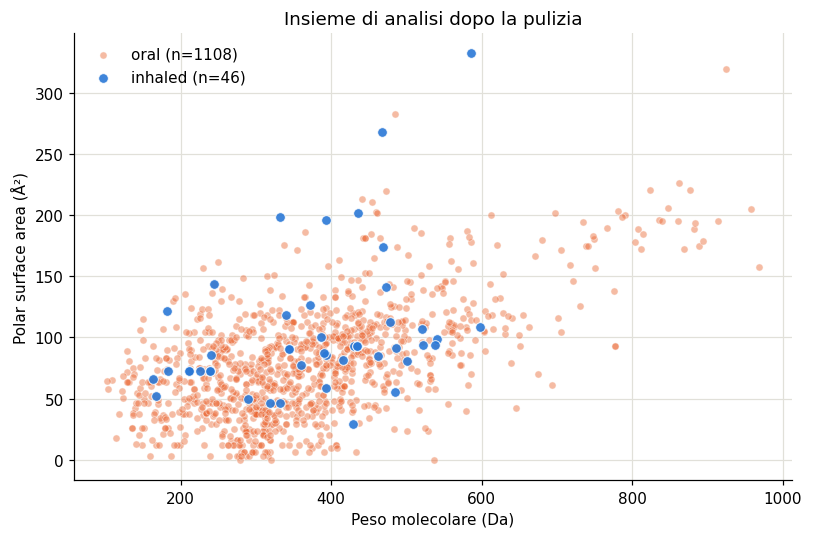

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for group in ["oral", "inhaled"]:
    d = dataset[dataset.route_group == group]
    ax.scatter(d.mw_freebase, d.psa, s=22 if group == "oral" else 40, alpha=0.45 if group == "oral" else 0.9,
               color=COLORS[group], edgecolor="white", linewidth=0.6, label=f"{group} (n={len(d)})")
ax.set_xlabel("Peso molecolare (Da)")
ax.set_ylabel("Polar surface area (Å²)")
ax.set_title("Insieme di analisi dopo la pulizia")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "inhaled_vs_oral_after_cleaning.png", bbox_inches="tight")
plt.show()

## Flusso delle esclusioni
Come un diagramma CONSORT negli studi clinici: dai record di partenza all'insieme analizzato, con il peso di ogni regola.

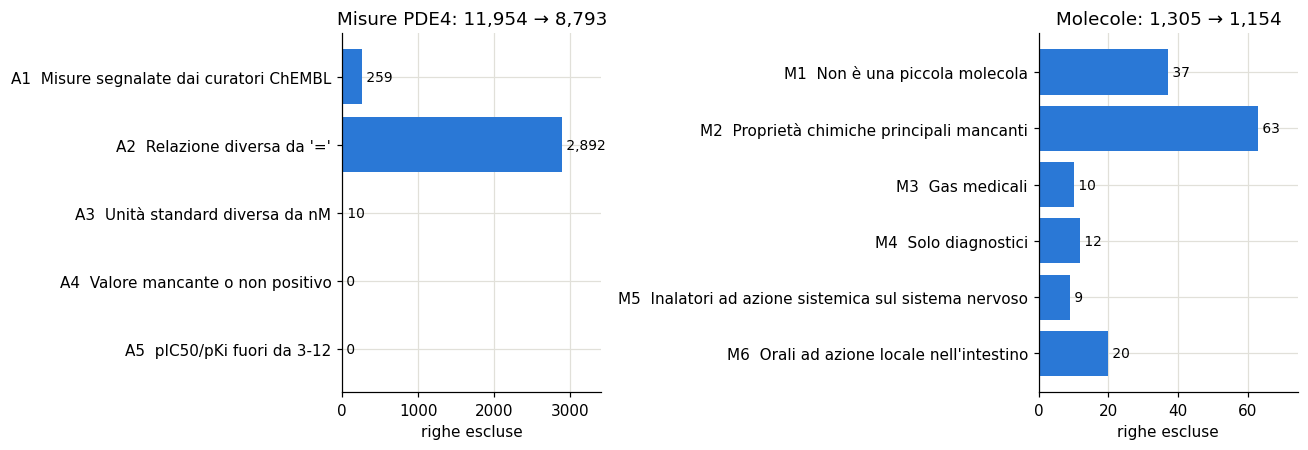

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, log, title in [(axes[0], log_a, "Misure PDE4"), (axes[1], log_m, "Molecole")]:
    steps = log[log.kind == "exclude"]
    labels = steps.rule_id + "  " + steps.rule.str.slice(0, 52)
    ax.barh(labels[::-1], steps.rows_removed[::-1], color="#2a78d6")
    for y, v in enumerate(steps.rows_removed[::-1]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=9)
    start, end = log.iloc[0].rows_after, steps.iloc[-1].rows_after
    ax.set_title(f"{title}: {start:,} → {end:,}")
    ax.set_xlabel("righe escluse")
    ax.margins(x=0.18)
fig.tight_layout()
fig.savefig(FIG / "exclusion_flow.png", bbox_inches="tight")
plt.show()

## Salvataggio e controlli di integrità
Le tabelle pulite e il registro vengono scritti nel database (la stessa app SQL li può interrogare), in `reports/cleaning_log.csv` e nella copia del database usata dall'app.

In [15]:
log = cleaning.save_outputs(con, [ledger_a, ledger_m], {
    "activities_clean": activities, "activity_potency": potency,
    "molecule_routes_clean": routes, "inhalation_dataset": dataset,
})

# Integrity: what was excluded + what was kept = what came in.
counts = dict(con.execute("""
    SELECT 'activities_clean', COUNT(*) FROM activities_clean UNION ALL
    SELECT 'activity_potency', COUNT(*) FROM activity_potency UNION ALL
    SELECT 'inhalation_dataset', COUNT(*) FROM inhalation_dataset UNION ALL
    SELECT 'excl_activities', COUNT(*) FROM cleaning_exclusions WHERE dataset = 'activities' UNION ALL
    SELECT 'excl_molecules', COUNT(*) FROM cleaning_exclusions WHERE dataset = 'molecules'
""").fetchall())
assert counts["activities_clean"] + counts["excl_activities"] == len(raw_activities)
assert counts["inhalation_dataset"] + counts["excl_molecules"] == log_m.iloc[0].rows_before
assert counts["excl_activities"] == log_a.rows_removed.sum() and counts["excl_molecules"] == log_m.rows_removed.sum()
pd.Series(counts, name="righe")

activities_clean      8793
activity_potency      6887
inhalation_dataset    1154
excl_activities       3161
excl_molecules         151
Name: righe, dtype: int64

## In sintesi
- Ogni esclusione ha una regola, un motivo scritto e un elenco dei record coinvolti: si può interrogare con SQL (`cleaning_log`, `cleaning_exclusions`).
- I controlli di integrità verificano che record esclusi + record tenuti = record di partenza.
- **Prossimo passo (notebook 03):** confronto statistico inalatori vs orali (Mann-Whitney, effect size, intervalli bootstrap) e analisi di sensibilità senza le molecole `also_oral`.